In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/newsCorpora.csv",
    sep="\t",
    header=None
)

df.head()

,0,1,2,3,4,5,6,7
0,1,"Fed official says weak data caused by weather,...",http://www.latimes.com/business/money/la-fi-mo...,Los Angeles Times,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.latimes.com,1394470370698
1,2,Fed's Charles Plosser sees high bar for change...,http://www.livemint.com/Politics/H2EvwJSK2VE6O...,Livemint,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.livemint.com,1394470371207
2,3,US open: Stocks fall after Fed official hints ...,http://www.ifamagazine.com/news/us-open-stocks...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371550
3,4,"Fed risks falling 'behind the curve', Charles ...",http://www.ifamagazine.com/news/fed-risks-fall...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371793
4,5,Fed's Plosser: Nasty Weather Has Curbed Job Gr...,http://www.moneynews.com/Economy/federal-reser...,Moneynews,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.moneynews.com,1394470372027


In [2]:
df.columns = [
    "ID", "TITLE", "URL", "PUBLISHER",
    "CATEGORY", "STORY", "HOSTNAME", "TIMESTAMP"
]

df.head()

,ID,TITLE,URL,PUBLISHER,CATEGORY,STORY,HOSTNAME,TIMESTAMP
0,1,"Fed official says weak data caused by weather,...",http://www.latimes.com/business/money/la-fi-mo...,Los Angeles Times,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.latimes.com,1394470370698
1,2,Fed's Charles Plosser sees high bar for change...,http://www.livemint.com/Politics/H2EvwJSK2VE6O...,Livemint,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.livemint.com,1394470371207
2,3,US open: Stocks fall after Fed official hints ...,http://www.ifamagazine.com/news/us-open-stocks...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371550
3,4,"Fed risks falling 'behind the curve', Charles ...",http://www.ifamagazine.com/news/fed-risks-fall...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371793
4,5,Fed's Plosser: Nasty Weather Has Curbed Job Gr...,http://www.moneynews.com/Economy/federal-reser...,Moneynews,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.moneynews.com,1394470372027


In [3]:
print("Total news articles:", df.shape[0])

print("\nNews Categories:")
print(df["CATEGORY"].value_counts())

print("\nMissing Values:")
print(df[["TITLE", "CATEGORY"]].isnull().sum())

Total news articles: 422419

News Categories:
CATEGORY
e    152469
b    115967
t    108344
m     45639
Name: count, dtype: int64

Missing Values:
TITLE       0
CATEGORY    0
dtype: int64


In [4]:
df = df[["TITLE", "CATEGORY"]].copy()

df = df.drop_duplicates()

df["TITLE"] = df["TITLE"].str.lower().str.strip()

print("Articles after cleaning:", len(df))
df.head()

Articles after cleaning: 407307


,TITLE,CATEGORY
0,"fed official says weak data caused by weather,...",b
1,fed's charles plosser sees high bar for change...,b
2,us open: stocks fall after fed official hints ...,b
3,"fed risks falling 'behind the curve', charles ...",b
4,fed's plosser: nasty weather has curbed job gr...,b


In [5]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df["CLEAN_TITLE"] = df["TITLE"].apply(clean_text)

df[["TITLE", "CLEAN_TITLE"]].head()

,TITLE,CLEAN_TITLE
0,"fed official says weak data caused by weather,...",fed official says weak data caused by weather ...
1,fed's charles plosser sees high bar for change...,fed s charles plosser sees high bar for change...
2,us open: stocks fall after fed official hints ...,us open stocks fall after fed official hints a...
3,"fed risks falling 'behind the curve', charles ...",fed risks falling behind the curve charles plo...
4,fed's plosser: nasty weather has curbed job gr...,fed s plosser nasty weather has curbed job growth


In [6]:
from sklearn.model_selection import train_test_split

X = df["CLEAN_TITLE"]
y = df["CATEGORY"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training articles:", len(X_train))
print("Testing articles:", len(X_test))


Training articles: 325845
Testing articles: 81462


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (325845, 10000)
Testing shape: (81462, 10000)


In [8]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [9]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test_tfidf)

print("Model Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Business", "Entertainment", "Health", "Technology"]
))

Model Accuracy: 93.8658515626918 %

Classification Report:
               precision    recall  f1-score   support

     Business       0.92      0.92      0.92     22381
Entertainment       0.96      0.98      0.97     29390
       Health       0.95      0.91      0.93      8744
   Technology       0.92      0.92      0.92     20947

     accuracy                           0.94     81462
    macro avg       0.94      0.93      0.93     81462
 weighted avg       0.94      0.94      0.94     81462



In [10]:
import pickle

with open("../models/news_model.pkl", "wb") as f:
    pickle.dump(model, f)

with open("../models/tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(tfidf, f)

print("Model and Vectorizer saved successfully!")

Model and Vectorizer saved successfully!


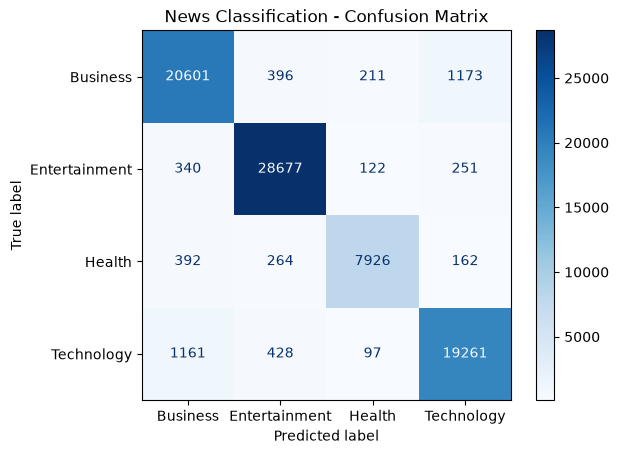

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Business", "Entertainment", "Health", "Technology"],
    cmap="Blues"
)

plt.title("News Classification - Confusion Matrix")
plt.show()

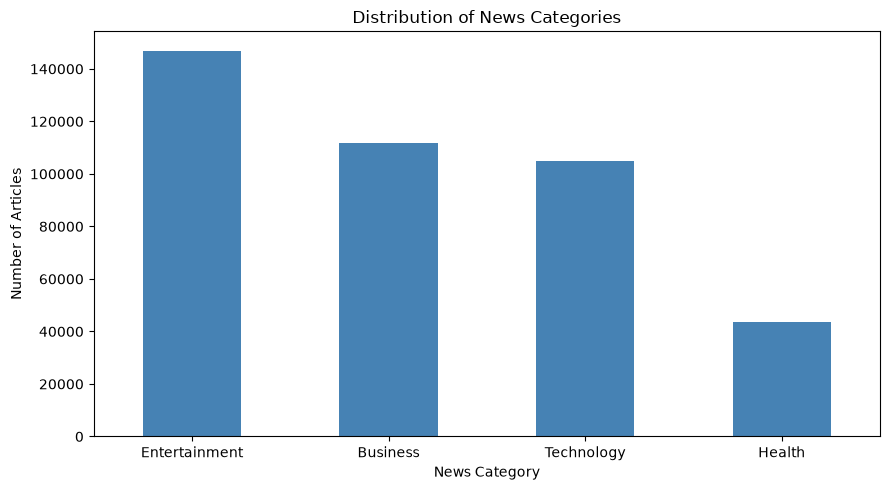

In [15]:
import matplotlib.pyplot as plt

category_names = {
    "b": "Business",
    "e": "Entertainment",
    "m": "Health",
    "t": "Technology"
}

counts = df["CATEGORY"].map(category_names).value_counts()

plt.figure(figsize=(9, 5))
counts.plot(kind="bar", color="steelblue")

plt.title("Distribution of News Categories")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../screenshots/category_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

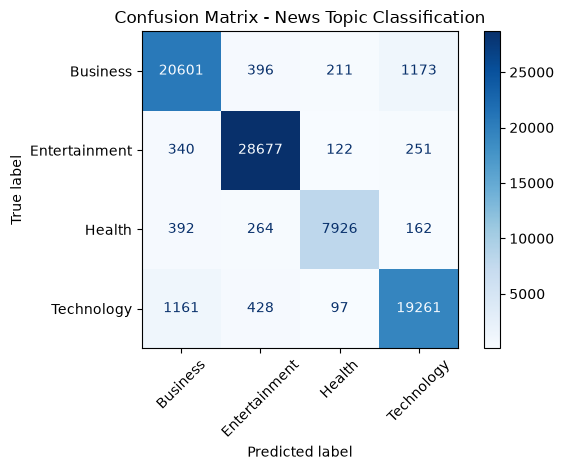

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Business", "Entertainment", "Health", "Technology"],
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Confusion Matrix - News Topic Classification")
plt.tight_layout()
plt.savefig("../screenshots/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()